# Cyclone Gabrielle Flood Map (Publication Figure)

Publication map of the U-Net flood map against the HBRC reference extent, with the flooded road segments. Writes `gabrielle_flood_map.pdf` and `.png` (300 dpi) to `figures/` at the repository root.

The classes are computed on the 10 m grid exactly as in cell 12 of `nzdf_flood_product.ipynb`:

- **Detected:** prediction and reference
- **Missed:** reference only
- **False alarm:** prediction only

**Before running:**
- Run `nzdf_flood_product.ipynb` first. This notebook reads its flood prediction GeoTIFF and the `road_segments_flooded` layer from `outputs/nzdf/`.
- Paths are relative to this notebook, so run it from `notebooks/`.

In [1]:
# Cell 1: Install dependencies
%pip install -q rasterio geopandas matplotlib-scalebar pyproj

Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import rasterio.features
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib_scalebar.scalebar import ScaleBar
from pyproj import Transformer

# -------------------------------------------------------------------------
# 1. Configuration
# -------------------------------------------------------------------------
# Paths are relative to this notebook (run it from notebooks/)
STACK_PATH = os.path.join('..', 'data', 'CycloneGabrielle_HawkesBay_S1_Stack_v2.tif')
PREDICTION_PATH = os.path.join('..', 'models', 'outputs', 'nzdf', 'UNet_Full_Scene_Flood_Prediction.tif')
PRODUCT_PATH = os.path.join('..', 'models', 'outputs', 'nzdf', 'nzdf_flood_product.gpkg')
REFERENCE_PATH = os.path.join('..', 'data', 'reference', 'Hawke_s_Bay_Flood_Observation_Extents',
                              'Hawke_s_Bay_Flood_Observation_Extents.shp')
OUT_PATH = os.path.join('..', 'figures', 'gabrielle_flood_map')  # .pdf and .png are added
STEP = 3  # Display downsampling factor (3 = 30 m pixels)

In [7]:
# -------------------------------------------------------------------------
# 2. Read Rasters and Classify
# -------------------------------------------------------------------------
with rasterio.open(STACK_PATH) as src:
    names = list(src.descriptions)
    post_vv = src.read(names.index("post_vv") + 1).astype("float32")
    transform, crs, (h, w) = src.transform, src.crs, (src.height, src.width)
with rasterio.open(PREDICTION_PATH) as src:
    pred = src.read(1)
valid = np.isfinite(post_vv) & (pred != 255)
pred = (pred == 1) & valid

ref_gdf = gpd.read_file(REFERENCE_PATH).to_crs(crs)
ref = rasterio.features.rasterize(((g, 1) for g in ref_gdf.geometry if g is not None and not g.is_empty),
                                  out_shape=(h, w), transform=transform, fill=0, dtype="uint8").astype(bool) & valid

classes = np.zeros((h, w), dtype="uint8")          # 0 = background
classes[ref & pred] = 1                            # detected
classes[ref & ~pred] = 2                           # missed
classes[pred & ~ref] = 3                           # false alarm
roads = gpd.read_file(PRODUCT_PATH, layer="road_segments_flooded").to_crs(crs)

print(f"detected {np.sum(classes == 1) / 1e4:.1f} km², missed {np.sum(classes == 2) / 1e4:.1f} km², "
      f"false alarm {np.sum(classes == 3) / 1e4:.1f} km²  (check against notebook cell 12: 35.3 / 113.9 / 2.6)")

detected 35.3 km², missed 113.9 km², false alarm 2.6 km²  (check against notebook cell 12: 35.3 / 113.9 / 2.6)


In [8]:
# -------------------------------------------------------------------------
# 3. Display Arrays (block-max keeps thin flood strips visible)
# -------------------------------------------------------------------------
s = STEP
H, W = h // s * s, w // s * s
bg = np.where(valid, post_vv, np.nan)[:H:s, :W:s]
cls = classes[:H, :W].reshape(H // s, s, W // s, s)
cls = np.max(np.where(cls == 1, 3, np.where(cls == 2, 2, np.where(cls == 3, 1, 0))), axis=(1, 3))
cls = np.choose(cls, [0, 3, 2, 1])               # priority detected > missed > false alarm, back to codes
left, top = transform.c, transform.f
extent = (left, left + W * transform.a, top + H * transform.e, top)

saved ../figures/gabrielle_flood_map.pdf


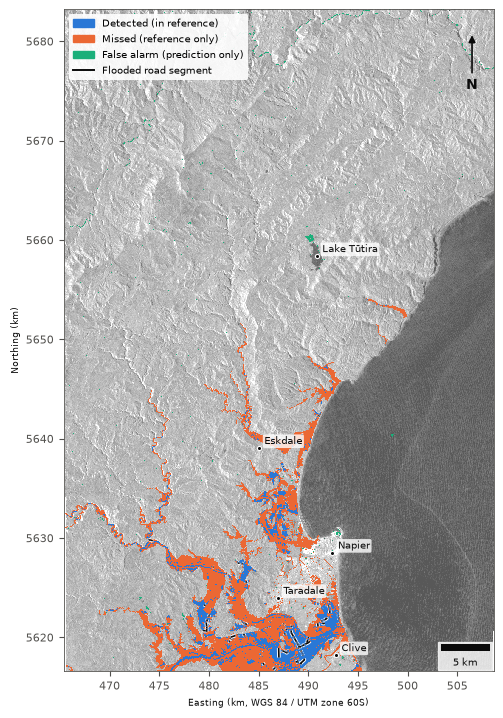

In [9]:
# -------------------------------------------------------------------------
# 4. Map
# -------------------------------------------------------------------------
INK, INK2 = "#0b0b0b", "#52514e"
C_DET, C_MISS, C_FA = "#2a78d6", "#eb6834", "#1baf7a"     # validated categorical slots 1-3
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8, "axes.labelsize": 8, "axes.edgecolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6})

fig, ax = plt.subplots(figsize=(6.3, 8.6))
ax.imshow(bg, cmap="gray", vmin=-25, vmax=0, extent=extent, interpolation="nearest")
ax.imshow(np.ones_like(bg), cmap=ListedColormap(["white"]), alpha=0.35, extent=extent)   # soften background
ax.imshow(np.ma.masked_equal(cls, 0), cmap=ListedColormap([C_DET, C_MISS, C_FA]), vmin=0.5, vmax=3.5,
          extent=extent, interpolation="nearest")
roads.plot(ax=ax, color="white", linewidth=2.6, zorder=4)
roads.plot(ax=ax, color=INK, linewidth=1.2, zorder=5)

# Place names (WGS84 -> scene CRS). Check positions against a basemap before submitting.
to_xy = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
places = {"Napier": (176.912, -39.493), "Taradale": (176.848, -39.534), "Clive": (176.916, -39.586),
          "Eskdale": (176.826, -39.398), "Lake Tūtira": (176.894, -39.224)}
for name, (lon, lat) in places.items():
    x, y = to_xy.transform(lon, lat)
    ax.plot(x, y, "o", ms=3, color=INK, mec="white", mew=0.8, zorder=6)
    ax.annotate(name, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK, zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))

# Axes in km (UTM zone 60S), scale bar, north arrow, legend
ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}"))
ax.set_xlabel("Easting (km, WGS 84 / UTM zone 60S)", color=INK)
ax.set_ylabel("Northing (km)", color=INK)
ax.add_artist(ScaleBar(1, "m", location="lower right", length_fraction=0.2, box_alpha=0.8,
                       font_properties={"size": 7.5}, color=INK))
ax.annotate("N", xy=(0.95, 0.965), xytext=(0.95, 0.885), xycoords="axes fraction", ha="center", va="center",
            fontsize=10, fontweight="bold", color=INK,
            arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.2), zorder=7)
handles = [Patch(color=C_DET, label="Detected (in reference)"),
           Patch(color=C_MISS, label="Missed (reference only)"),
           Patch(color=C_FA, label="False alarm (prediction only)"),
           Line2D([], [], color=INK, lw=1.4, label="Flooded road segment")]
ax.legend(handles=handles, loc="upper left", fontsize=7.5, framealpha=0.9, edgecolor="none")

out = Path(OUT_PATH); out.parent.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(out.with_suffix(f".{ext}"), dpi=300, bbox_inches="tight")
print("saved", out.with_suffix(".pdf"))
plt.show()